# Low-rank completion and a spectral dual certificate

A masked squared-error objective with a uniform nuclear penalty is convex. Exact SVD shrinkage and feasible spectral dual bounds differ from the degree-regularized biased MovieLens objective.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Missing entries are excluded

In [2]:
from optimization_lab.first_order import nuclear_completion
y=np.array([[4.,np.nan],[np.nan,2.]])
result=nuclear_completion(y,np.isfinite(y),1.)
assert np.allclose(result["x"],np.diag([3.,1.]))
print(result["certificate"])

{'objective': 5.0, 'dual_objective': 4.999999999996, 'gap': 4.000355602329364e-12, 'dual_spectral_norm': 0.9999999999989999}


## Every synthetic fit

In [3]:
rows=[]
for seed in [0,1,2]:
    rows += [dict(seed=seed,method=r["method"],heldout_rmse=r["unobserved_rmse_to_synthetic_truth"],gap=r["certificate"]["gap"]) for r in read(f"results/reference/first_order/nuclear_seed{seed}/metrics.json")["rows"]]
pd.DataFrame(rows)

,seed,method,heldout_rmse,gap
0,0,ista,0.122565,9.912821e-07
1,0,fista,0.122565,6.453042e-07
2,1,ista,0.073860,9.830710e-07
3,1,fista,0.073860,5.411172e-07
4,2,ista,0.196787,9.871968e-07
5,2,fista,0.196786,6.381653e-07


## Reconstruction evidence

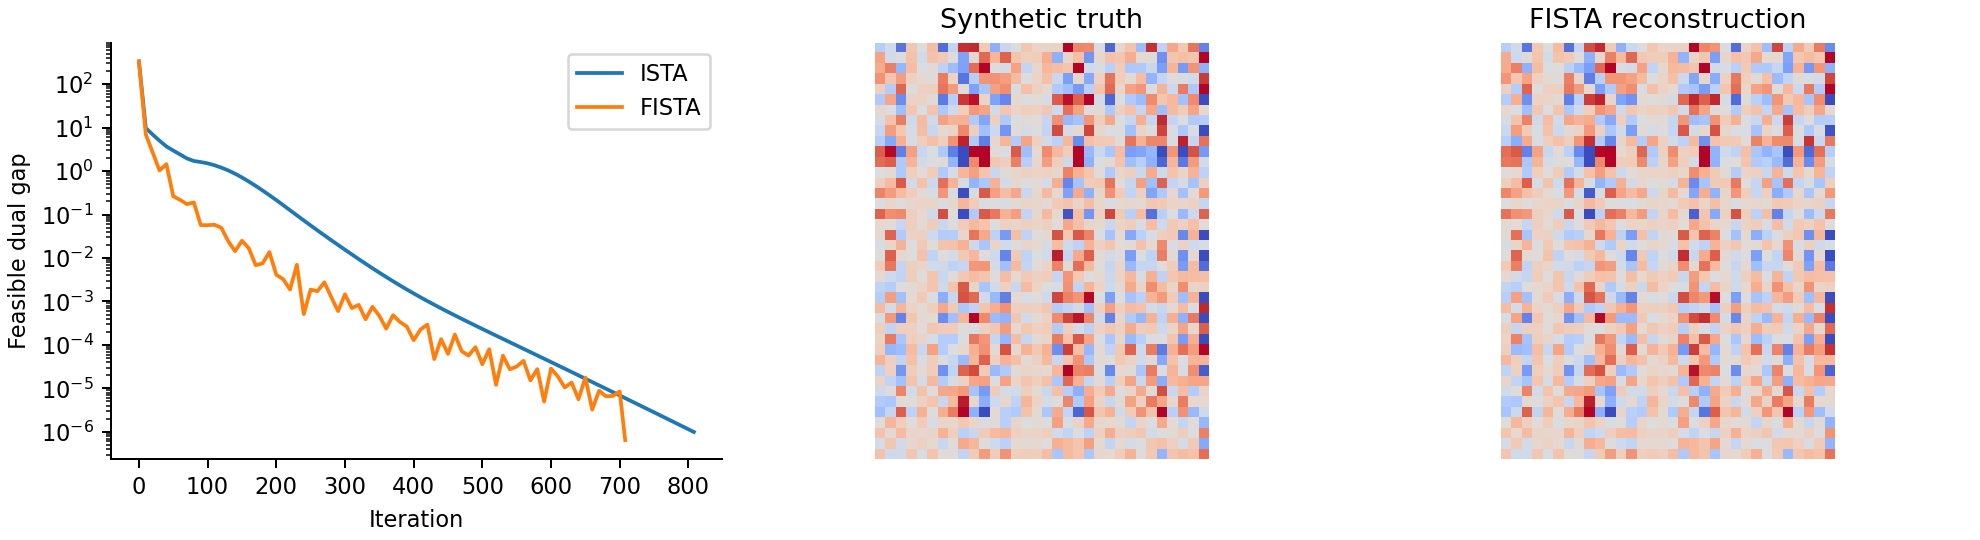

In [4]:
figure("nuclear_completion_seed0")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.